# 63. Sediment Nutrient Correlation with PCA

In [1]:
# Setup and Imports
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
from scipy.stats import pearsonr
import logging
import warnings
warnings.filterwarnings('ignore')

project_root = Path('/home/reyha/SIS_Analysis_WSL').resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))
if str(project_root / 'scripts') not in sys.path:
    sys.path.append(str(project_root / 'scripts'))

from utils.paths import ProjectPaths
from utils.mapping_config import MappingConfig

# Apply the global project style
plt.style.use(str(ProjectPaths.PROJECT_ROOT / 'project_style.mplstyle'))

# Ensure output directory
OUTPUT_DIR = ProjectPaths.FIGURES_DIR / 'step0_sandbox' / '63_sediment_nutrient_correlation'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [2]:
# 1. Load PCA Scores
season = 'Summer'
layer = 'bottom'
subset_dir = ProjectPaths.get_subset_dir(season, layer)
pca_scores = pd.read_csv(subset_dir / 'pca_scores.csv', index_col=0)
pca_scores.index = pca_scores.index.astype(int)

# 2. Load and Clean Sediment Data
bottom_path = ProjectPaths.DATA_DIR / 'raw' / 'benthos_data' / 'bottom_2023.xlsx'
print(f'Loading bottom sediment data from {bottom_path}...')
df_bottom_raw = pd.read_excel(bottom_path, sheet_name='底質_累積2023')
df_bottom = df_bottom_raw.copy()

df_bottom['year'] = df_bottom['年']
def dms_to_dd(d, m, s): return d + m / 60.0 + s / 3600.0
df_bottom['lat'] = dms_to_dd(df_bottom['緯度_度'], df_bottom['緯度_分'], df_bottom['緯度_秒'])
df_bottom['lon'] = dms_to_dd(df_bottom['経度_度'], df_bottom['経度_分'], df_bottom['経度_秒'])

df_bottom['TN'] = pd.to_numeric(df_bottom['TN'], errors='coerce')

# --- NEW CLEANING STEPS ---
# Standardize station codes to uppercase to fix inconsistent casing (e.g., Ykg-3 vs YKG-3)
if '連番' in df_bottom.columns:
    df_bottom['連番'] = df_bottom['連番'].astype(str).str.upper()

# Filter only for Summer samples (August) to prevent averaging different seasonal replicates in the same year
df_bottom = df_bottom[df_bottom['月'] == 8].copy()
# --------------------------

# Filter and cut PCA time series to match sediment data temporal dimension
min_year = int(df_bottom['year'].min())
max_year = int(df_bottom['year'].max())
pca_scores = pca_scores.loc[min_year:max_year]

print(f"PCA scores filtered to years {min_year} - {max_year}")
print(f"Sediment data filtered to Summer samples only: {len(df_bottom)} records remain.")


Loading bottom sediment data from /home/reyha/SIS_Analysis_WSL/data/raw/benthos_data/bottom_2023.xlsx...
PCA scores filtered to years 1991 - 2023
Sediment data filtered to Summer samples only: 363 records remain.


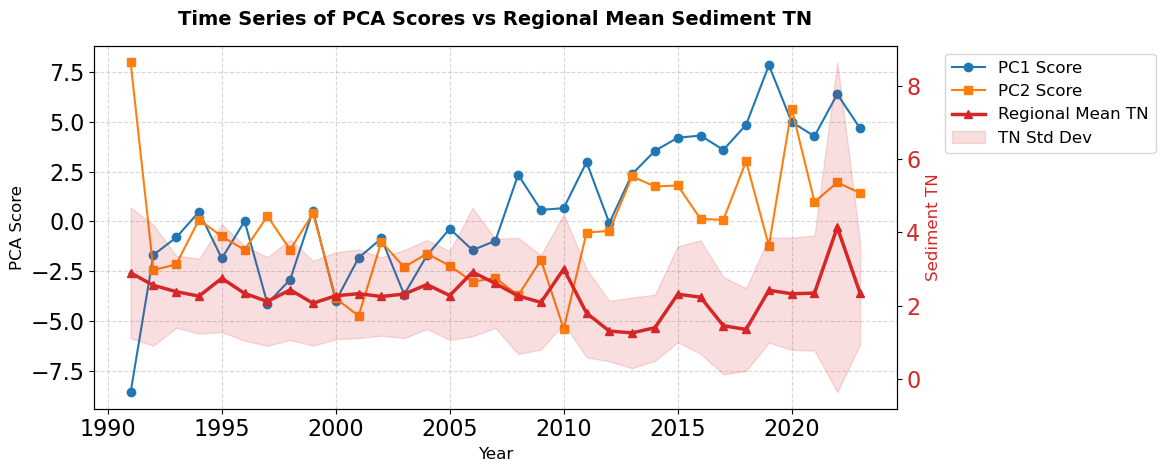

In [3]:
# Calculate the regional annual mean and standard deviation for Sediment TN
regional_tn_mean = df_bottom.groupby('year')['TN'].mean()
regional_tn_std = df_bottom.groupby('year')['TN'].std()

fig, ax1 = plt.subplots(figsize=(12, 5))

# Plot PCA Scores on the primary y-axis
ax1.plot(pca_scores.index, pca_scores['PC1'], label='PC1 Score', marker='o', color='tab:blue')
ax1.plot(pca_scores.index, pca_scores['PC2'], label='PC2 Score', marker='s', color='tab:orange')
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('PCA Score', fontsize=12)
ax1.grid(True, linestyle='--', alpha=0.5)

# Create a secondary y-axis for the Sediment TN
ax2 = ax1.twinx()
ax2.plot(regional_tn_mean.index, regional_tn_mean.values, label='Regional Mean TN', marker='^', color='tab:red', linewidth=2.5)
ax2.fill_between(regional_tn_mean.index, 
                 regional_tn_mean - regional_tn_std, 
                 regional_tn_mean + regional_tn_std, 
                 color='tab:red', alpha=0.15, label='TN Std Dev')

ax2.set_ylabel('Sediment TN', fontsize=12, color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

# Combine legends from both axes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', bbox_to_anchor=(1.05, 1))

plt.title('Time Series of PCA Scores vs Regional Mean Sediment TN', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [4]:
# Group sediment data by location and year to get time series per station
# Some stations might have slight coordinate variations, we round lat/lon to group them
df_bottom['lat_r'] = df_bottom['lat'].round(4)
df_bottom['lon_r'] = df_bottom['lon'].round(4)

# Create a pivot table of TN where rows are years and columns are stations (lat_r, lon_r)
tn_mat = df_bottom.groupby(['year', 'lat_r', 'lon_r'])['TN'].mean().unstack(level=['lat_r', 'lon_r'])

correlations = []

for stn in tn_mat.columns:
    s_pc1 = pca_scores['PC1']
    s_pc2 = pca_scores['PC2']
    s_env = tn_mat[stn]
    
    common = s_pc1.index.intersection(s_env.index)
    valid = s_pc1.loc[common].notna() & s_env.loc[common].notna()
    if valid.sum() >= 5:
        r1, p1 = pearsonr(s_pc1.loc[common][valid], s_env.loc[common][valid])
        r2, p2 = pearsonr(s_pc2.loc[common][valid], s_env.loc[common][valid])
        correlations.append({
            'latitude': stn[0],
            'longitude': stn[1],
            'PC1': r1,
            'PC1_pval': p1,
            'PC2': r2,
            'PC2_pval': p2
        })

df_corr = pd.DataFrame(correlations)
print(f"Computed correlations for {len(df_corr)} stations.")
display(df_corr.head())


Computed correlations for 23 stations.


,latitude,longitude,PC1,PC1_pval,PC2,PC2_pval
0,35.4642,139.8561,-0.641049,0.024680,0.469159,0.123882
1,35.5372,140.0225,-0.392303,0.232727,0.320275,0.336953
2,35.5511,139.9089,-0.230170,0.495947,0.494139,0.122361
3,35.5600,139.8244,-0.333750,0.289051,0.320046,0.310511
4,35.6017,140.0642,-0.110075,0.747313,0.282111,0.400634


In [5]:
def plot_sediment_correlation(plot_data, parameter, pc_name, title, output_filename, target_region="Seto Inland Sea"):
    p_col = parameter + '_pval'
    plot_data = plot_data.dropna(subset=[parameter, p_col]).copy()
    
    if plot_data.empty:
        print(f"No correlation data available for {title}")
        return

    # Base Figure Setup matching process41
    water_boundary_files = {
        'Seto Inland Sea': 'sea_area_mask_sis_simplified.shp',
        'Tokyo Bay': 'sea_area_mask_Tokyo.shp',
        'Ise Bay': 'sea_area_mask_Ise.shp'
    }
    water_boundary_file = water_boundary_files.get(target_region, 'sea_area_mask_sis_simplified.shp')
    water_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS water mass polygon" / water_boundary_file
    
    if water_boundary_path.exists():
        sis_water_boundary = gpd.read_file(water_boundary_path)
        if sis_water_boundary.crs != "EPSG:4326":
            sis_water_boundary = sis_water_boundary.to_crs("EPSG:4326")
        
        # Filter plot_data to points that fall within the bounding box of the target region
        minx, miny, maxx, maxy = sis_water_boundary.total_bounds
        plot_data = plot_data[
            (plot_data['longitude'] >= minx) & (plot_data['longitude'] <= maxx) &
            (plot_data['latitude'] >= miny) & (plot_data['latitude'] <= maxy)
        ]
        
    if plot_data.empty:
        print(f"No correlation data available in {target_region} for {title}")
        return
    
    # Use dynamic extent with 0.2 buffer based on filtered points
    minx, maxx = plot_data['longitude'].min(), plot_data['longitude'].max()
    miny, maxy = plot_data['latitude'].min(), plot_data['latitude'].max()
    buffer = 0.2
    extent = [minx - buffer, maxx + buffer, miny - buffer, maxy + buffer]

    aspect_ratio = (extent[3] - extent[2]) / (extent[1] - extent[0])
    if aspect_ratio > 1:
        fig_height = 10
        fig_width = fig_height / aspect_ratio
    else:
        fig_width = 10
        fig_height = fig_width * aspect_ratio
        
    single_fig_height = fig_height + 1.4
    
    fig = plt.figure(figsize=(fig_width, single_fig_height))
    ax = plt.axes(projection=ccrs.PlateCarree())
    
    ax.set_facecolor(MappingConfig.COLOR_OCEAN if hasattr(MappingConfig, 'COLOR_OCEAN') else 'lightblue')
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, edgecolor='gray', zorder=MappingConfig.ZORDER_CARTOPY_LAND)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
    
    # Add High-Res Coastlines (Land Boundary)
    if hasattr(MappingConfig, 'get_boundary_file'):
        land_boundary_file = MappingConfig.get_boundary_file(target_region)
    else:
        land_boundary_file = "polbnda_jpn.shp"
        
    land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / land_boundary_file
    
    if land_boundary_path.exists():
        sis_land_boundary = gpd.read_file(land_boundary_path)
        if sis_land_boundary.crs != "EPSG:4326":
            sis_land_boundary = sis_land_boundary.to_crs("EPSG:4326")
        sis_land_boundary.plot(
            ax=ax,
            facecolor=MappingConfig.COLOR_LAND,
            edgecolor=getattr(MappingConfig, 'COLOR_LAND_EDGE', 'gray'),
            linewidth=MappingConfig.LINEWIDTH_LAND,
            transform=ccrs.PlateCarree(),
            zorder=MappingConfig.ZORDER_LAND
        )
    
    MappingConfig.apply_gridlines(ax)
    
    colors = []
    sizes = []
    cmap = plt.get_cmap('coolwarm')
    norm = mcolors.Normalize(vmin=-1, vmax=1)
    
    for val, p_val in zip(plot_data[parameter], plot_data[p_col]):
        if p_val <= 0.001: size = 500
        elif p_val <= 0.01: size = 300
        elif p_val <= 0.05: size = 150
        else: size = 20
        sizes.append(size)
        
        if val < -0.75: color = cmap(0.0)
        elif val < -0.5: color = cmap(0.15)
        elif val < -0.25: color = cmap(0.3)
        elif val < 0: color = cmap(0.45)
        elif val < 0.25: color = cmap(0.55)
        elif val < 0.5: color = cmap(0.7)
        elif val < 0.75: color = cmap(0.85)
        else: color = cmap(1.0)
        colors.append(color)

    ax.scatter(
        plot_data['longitude'],
        plot_data['latitude'],
        c=colors,
        s=sizes,
        edgecolors='k',
        linewidths=0.5,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_PREDICTED,
        alpha=1
    )
    
    plt.title(title, pad=20, fontsize=20, fontweight='bold')
    
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    ticks = [-1.0, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1.0]
    
    cbar_ax = fig.add_axes([0.92, 0.15, 0.03, 0.7]) 
    cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical', ticks=ticks)
    cbar.set_label('Pearson Correlation (Red=Positive, Blue=Negative)', fontsize=14) 
    
    plt.savefig(OUTPUT_DIR / output_filename, dpi=300, bbox_inches='tight')
    plt.show()

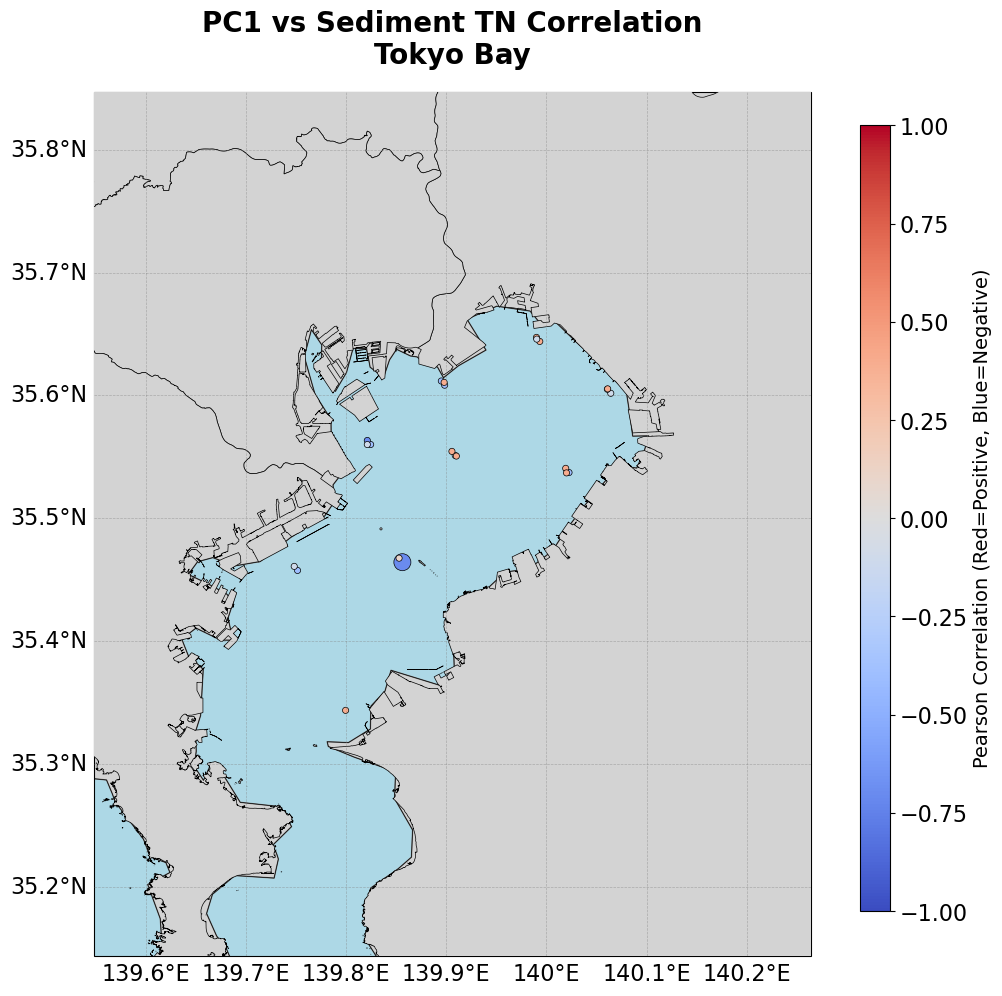

In [6]:
# Plot PC1 Correlation for Tokyo Bay
plot_sediment_correlation(
    df_corr, 
    parameter='PC1', 
    pc_name='PC1', 
    title="PC1 vs Sediment TN Correlation\nTokyo Bay", 
    output_filename="spatial_corr_map_sediment_TN_PC1_Tokyo.png",
    target_region="Tokyo Bay"
)

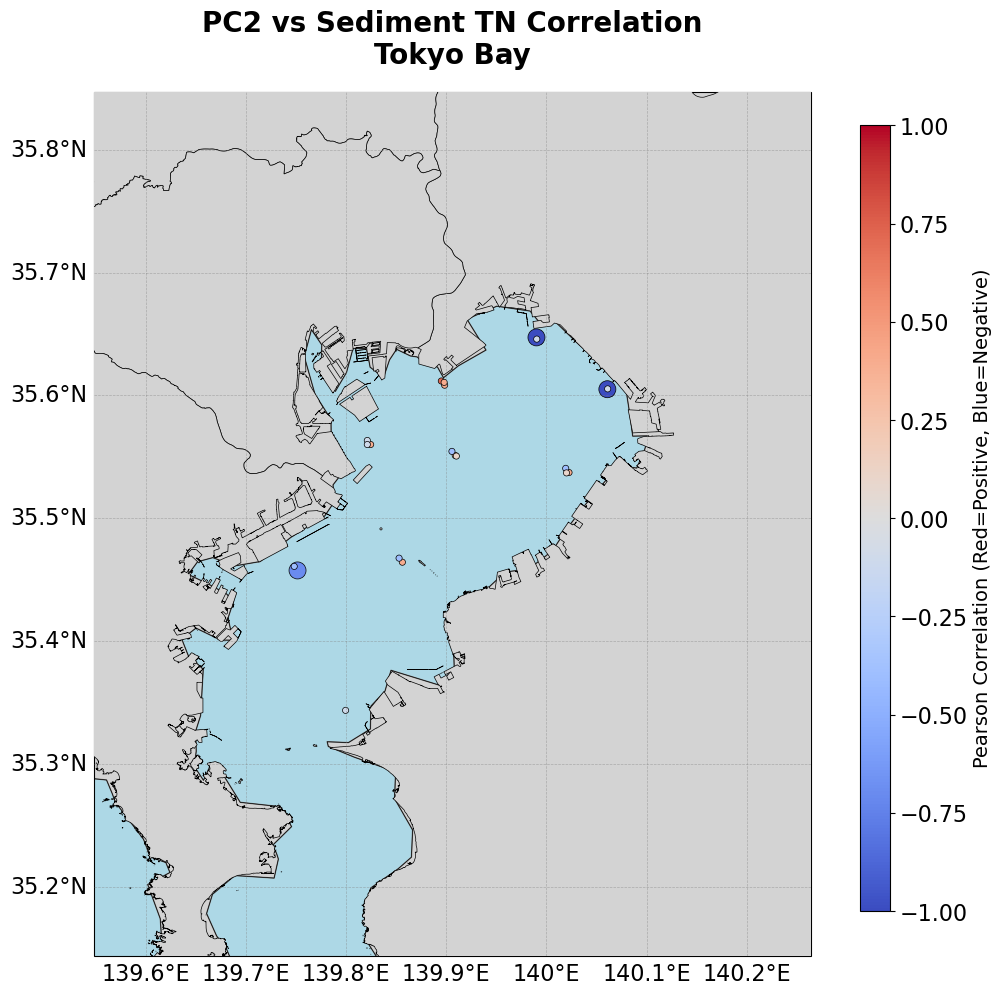

In [7]:
# Plot PC2 Correlation for Tokyo Bay
plot_sediment_correlation(
    df_corr, 
    parameter='PC2', 
    pc_name='PC2', 
    title="PC2 vs Sediment TN Correlation\nTokyo Bay", 
    output_filename="spatial_corr_map_sediment_TN_PC2_Tokyo.png",
    target_region="Tokyo Bay"
)